[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch16_KidsLab04_Fashion_MNIST_CNN.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 16: Building Real CNNs: Fashion-MNIST and CIFAR-10** (Part III: Seeing). Also used in Chapters 11, 12. This lab comes from the simplified video course for kids, kept for comparison.

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=16](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=16)
* The simplified video course for kids that this book grew from: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# 👕 Interactive Fashion Recognition (10 Categories)
## Train AI & Upload YOUR Fashion Drawing!

**What you'll do:**
1. Explore Fashion MNIST items interactively
2. Build & train a CNN (Convolutional Neural Network)
3. Upload your own fashion drawing and watch AI classify it!

**Fashion Categories:**
- 0: T-shirt/top
- 1: Trouser
- 2: Pullover
- 3: Dress
- 4: Coat
- 5: Sandal
- 6: Shirt
- 7: Sneaker
- 8: Bag
- 9: Ankle boot

---

> ### ✅ Checked edition (November 2026)
> This notebook was re-run top to bottom and checked for *The Why Book of Deep Learning, Part 1*. What changed from the original:
>
> * **Early stopping by default.** The original trained for a fixed 200 epochs and told you "more epochs = more learning". Its own log disagrees: the best validation loss came at epoch 12 and was about 4.7 times worse by epoch 200 (0.24 to 1.13; Chapter 11 of the book reads that log). Training now stops when the validation loss stops improving and restores the best weights. One switch, `REPRODUCE_ORIGINAL_200_EPOCHS = True`, brings back the original run as an experiment.
> * **Runs outside Colab too**, with a demo drawing when nothing is uploaded (or your own files in `MY_IMAGES`).
> * **Drawings now look like Fashion-MNIST.** The old preprocessing kept only a thin, thresholded outline; Fashion-MNIST items are filled. The new function fills the outline (keeping small openings like a handle), crops it and scales the longest side to 28 pixels. Tested on four demo drawings with a quickly trained copy of this CNN: 2/4 right before, 4/4 after.
> * `keras.utils.set_random_seed(42)` makes the run repeatable (the original's saved outputs mixed two different runs); `keras.Input` replaces the deprecated `input_shape=`; one log line per epoch.
> * "Trained on 60,000 images" corrected to 54,000 (+6,000 for validation); the explorer now really shows one example of each category.

## 📦 Cell 1: Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import fashion_mnist

keras.utils.set_random_seed(42)   # Python, NumPy and TensorFlow in one call: the same run every time

print("✅ Libraries loaded!")
print(f"TensorFlow: {tf.__version__}")

✅ Libraries loaded!
TensorFlow: 2.21.0


---
## 📊 Cell 2: Load Fashion MNIST Dataset

In [2]:
print("📥 Loading Fashion MNIST dataset...\n")

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Fashion class names
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print(f"✅ Fashion MNIST loaded!")
print(f"Training images: {X_train.shape[0]:,}")
print(f"Test images: {X_test.shape[0]:,}")
print(f"Image size: {X_train.shape[1]}×{X_train.shape[2]} pixels")
print(f"\n👕 Fashion Categories:")
for i, name in enumerate(class_names):
    print(f"  {i}: {name}")

📥 Loading Fashion MNIST dataset...



✅ Fashion MNIST loaded!
Training images: 60,000
Test images: 10,000
Image size: 28×28 pixels

👕 Fashion Categories:
  0: T-shirt/top
  1: Trouser
  2: Pullover
  3: Dress
  4: Coat
  5: Sandal
  6: Shirt
  7: Sneaker
  8: Bag
  9: Ankle boot


---
## 🎨 Cell 3: Interactive Fashion MNIST Explorer!

**Enter a number (0-59999) to see that specific fashion item from the training set!**

🎯 Try different numbers to explore the dataset!

🔍 Showing the first example of each category:



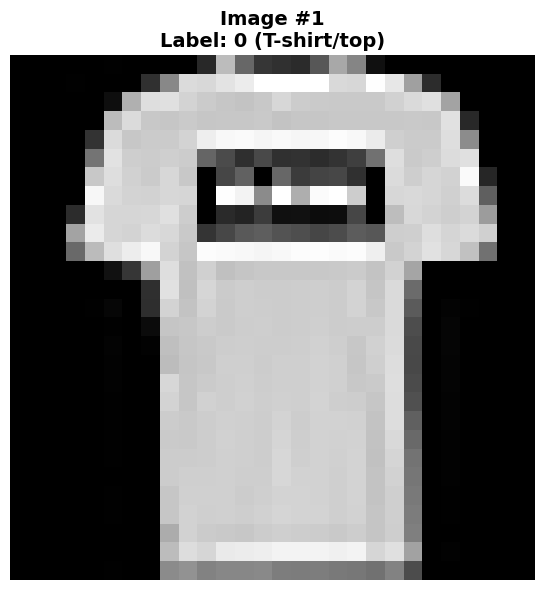


📊 Image Details:
  Index: 1
  Label: 0
  Category: T-shirt/top
  Shape: (28, 28)
  Pixel range: 0 to 255


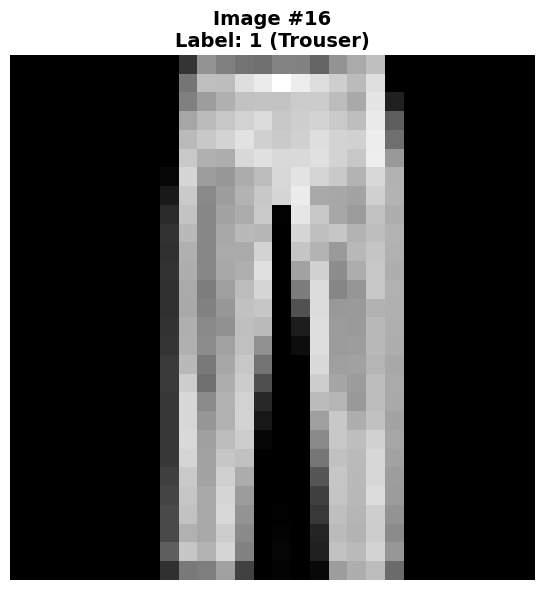


📊 Image Details:
  Index: 16
  Label: 1
  Category: Trouser
  Shape: (28, 28)
  Pixel range: 0 to 254


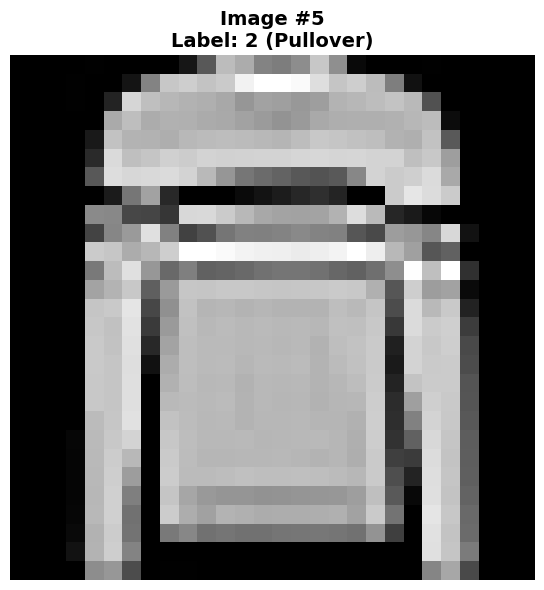


📊 Image Details:
  Index: 5
  Label: 2
  Category: Pullover
  Shape: (28, 28)
  Pixel range: 0 to 255


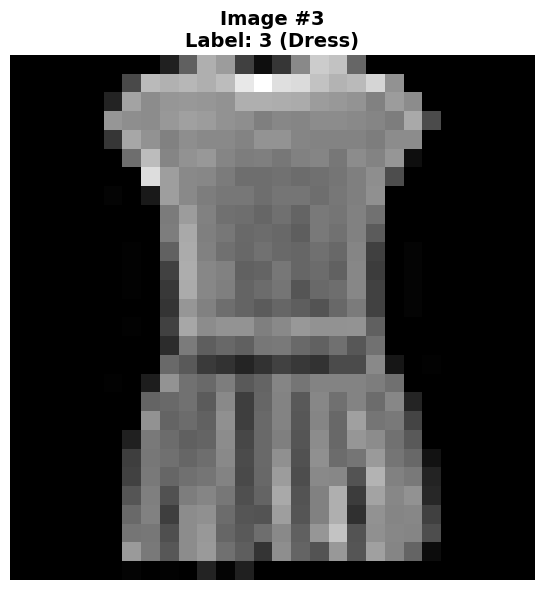


📊 Image Details:
  Index: 3
  Label: 3
  Category: Dress
  Shape: (28, 28)
  Pixel range: 0 to 255


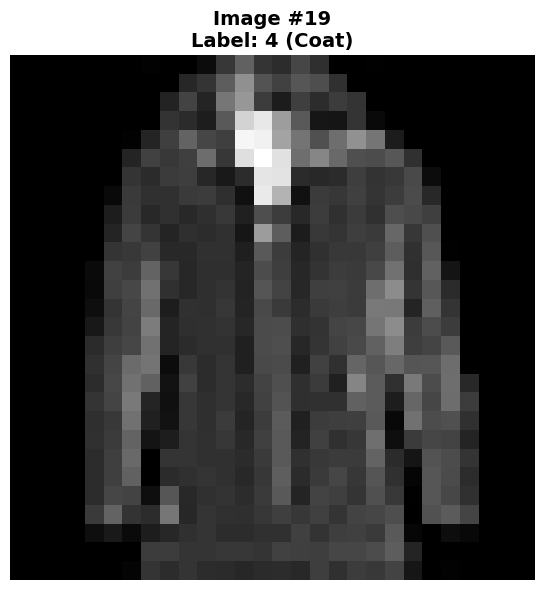


📊 Image Details:
  Index: 19
  Label: 4
  Category: Coat
  Shape: (28, 28)
  Pixel range: 0 to 255


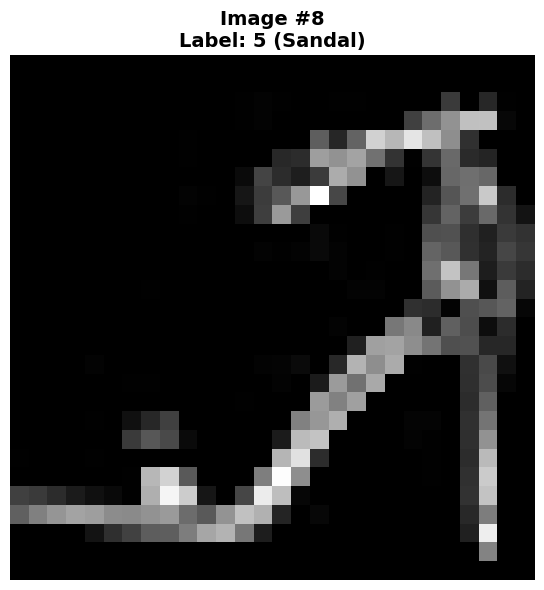


📊 Image Details:
  Index: 8
  Label: 5
  Category: Sandal
  Shape: (28, 28)
  Pixel range: 0 to 255


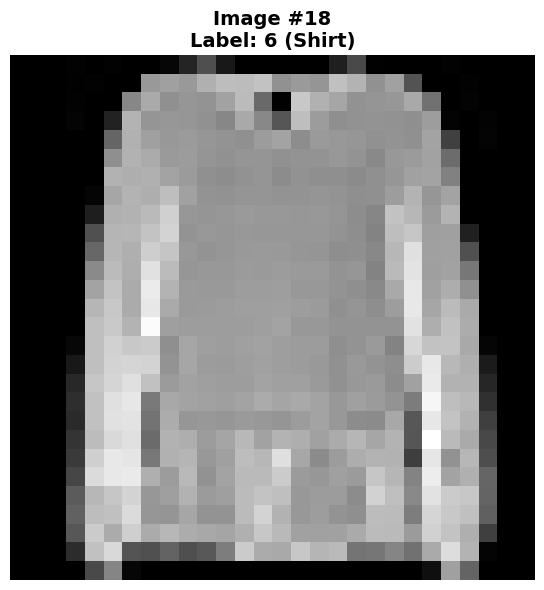


📊 Image Details:
  Index: 18
  Label: 6
  Category: Shirt
  Shape: (28, 28)
  Pixel range: 0 to 255


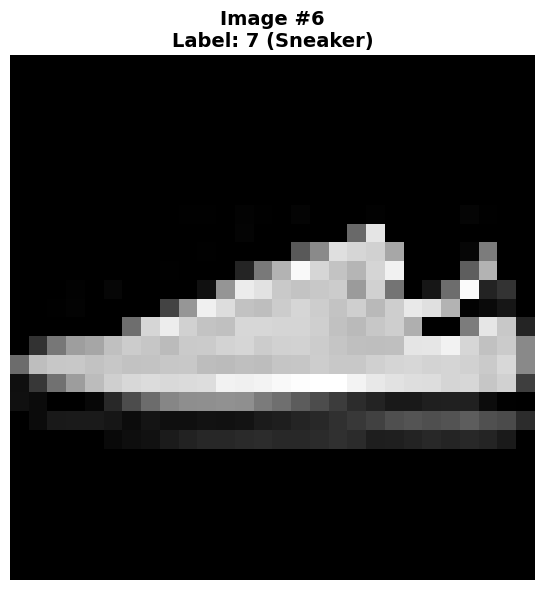


📊 Image Details:
  Index: 6
  Label: 7
  Category: Sneaker
  Shape: (28, 28)
  Pixel range: 0 to 255


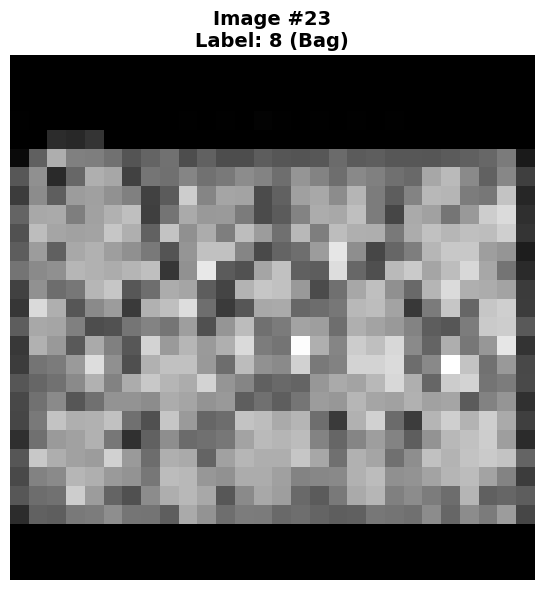


📊 Image Details:
  Index: 23
  Label: 8
  Category: Bag
  Shape: (28, 28)
  Pixel range: 0 to 255


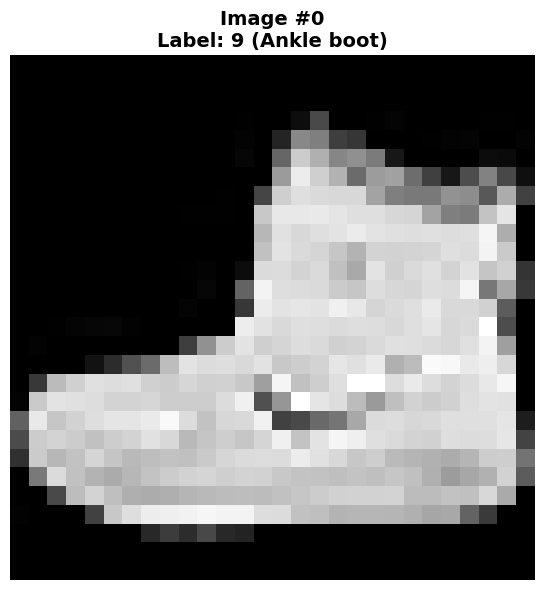


📊 Image Details:
  Index: 0
  Label: 9
  Category: Ankle boot
  Shape: (28, 28)
  Pixel range: 0 to 255


In [3]:
print("🎯 Try different numbers to explore the dataset!\n")

# Interactive function
def explore_fashion(index=0):
    if index < 0 or index >= len(X_train):
        print(f"❌ Please enter a number between 0 and {len(X_train)-1}")
        return

    plt.figure(figsize=(6, 6))
    plt.imshow(X_train[index], cmap='gray')
    plt.title(f"Image #{index}\nLabel: {y_train[index]} ({class_names[y_train[index]]})",
              fontsize=14, fontweight='bold')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    print(f"\n📊 Image Details:")
    print(f"  Index: {index}")
    print(f"  Label: {y_train[index]}")
    print(f"  Category: {class_names[y_train[index]]}")
    print(f"  Shape: {X_train[index].shape}")
    print(f"  Pixel range: {X_train[index].min()} to {X_train[index].max()}")

# Show some examples
print("🔍 Showing the first example of each category:\n")
for c in range(10):
    explore_fashion(int(np.where(y_train == c)[0][0]))

---
## 🔧 Cell 4: Preprocess Data for CNN

CNNs need the data in a specific format:
- Reshape: (samples, height, width, channels)
- Normalize: pixel values from 0-255 to 0-1
- One-hot encode labels

In [4]:
print("🔧 Preprocessing data for CNN...\n")

# Reshape for CNN (add channel dimension)
X_train_cnn = X_train.reshape(-1, 28, 28, 1).astype('float32')
X_test_cnn = X_test.reshape(-1, 28, 28, 1).astype('float32')

# Normalize pixel values (0-255 → 0-1)
X_train_cnn = X_train_cnn / 255.0
X_test_cnn = X_test_cnn / 255.0

# One-hot encode labels
y_train_cat = keras.utils.to_categorical(y_train, 10)
y_test_cat = keras.utils.to_categorical(y_test, 10)

print("✅ Preprocessing complete!")
print(f"\n📊 Data shapes:")
print(f"  X_train_cnn: {X_train_cnn.shape}")
print(f"  X_test_cnn: {X_test_cnn.shape}")
print(f"  y_train_cat: {y_train_cat.shape}")
print(f"  y_test_cat: {y_test_cat.shape}")
print(f"\n  Pixel range: {X_train_cnn.min():.1f} to {X_train_cnn.max():.1f}")

🔧 Preprocessing data for CNN...



✅ Preprocessing complete!

📊 Data shapes:
  X_train_cnn: (60000, 28, 28, 1)
  X_test_cnn: (10000, 28, 28, 1)
  y_train_cat: (60000, 10)
  y_test_cat: (10000, 10)

  Pixel range: 0.0 to 1.0


---
## 🏗️ Cell 5: Build CNN Model

**CNN Architecture:**
- Conv2D Layer 1: 32 filters, 3×3 kernel
- MaxPooling2D: 2×2
- Conv2D Layer 2: 64 filters, 3×3 kernel
- MaxPooling2D: 2×2
- Conv2D Layer 3: 64 filters, 3×3 kernel
- Flatten
- Dense: 128 neurons
- Dropout: 0.5
- Output: 10 classes (softmax)

In [5]:
print("🏗️ Building CNN model...\n")

model = keras.Sequential([
    # First Convolutional Block
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Second Convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Third Convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Flatten and Dense Layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("✅ CNN model built!\n")
model.summary()

🏗️ Building CNN model...



✅ CNN model built!



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

---
## 🎯 Cell 6: Train the CNN (with early stopping)

Watch the training progress:
- Training loss keeps going down, epoch after epoch
- **Validation loss** goes down for a while, then turns back **up**: from there on the model is memorising
  the training pictures instead of learning about clothes

**Early stopping** watches the validation loss, stops when it has not improved for 5 epochs, and puts back the
weights from the best epoch. That usually happens after about 15 to 20 epochs.

> **The experiment worth doing once:** set `REPRODUCE_ORIGINAL_200_EPOCHS = True` and train for all 200 epochs,
> as the first version of this notebook did. It takes about ten times longer, and the validation loss ends far
> *worse* than at its best epoch (the book's Chapter 11 reads that log line by line). More epochs is not more learning.

In [6]:
REPRODUCE_ORIGINAL_200_EPOCHS = False   # True = all 200 epochs, no early stopping (the original run)

callbacks = [] if REPRODUCE_ORIGINAL_200_EPOCHS else [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)]
print("🎯 Training (up to 200 epochs" + ("" if REPRODUCE_ORIGINAL_200_EPOCHS else ", stopping early") + ")...\n")

history = model.fit(
    X_train_cnn, y_train_cat,
    epochs=200,
    batch_size=128,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=2            # one line per epoch
)

epochs_run = len(history.history['loss'])
best_epoch = int(np.argmin(history.history['val_loss'])) + 1
print(f"\n✅ Training complete after {epochs_run} epochs.")
print(f"   Best validation loss {min(history.history['val_loss']):.4f} at epoch {best_epoch}"
      + ("" if REPRODUCE_ORIGINAL_200_EPOCHS else " (those weights were restored)"))

🎯 Training (up to 200 epochs, stopping early)...



Epoch 1/200


422/422 - 10s - 24ms/step - accuracy: 0.7303 - loss: 0.7318 - val_accuracy: 0.8335 - val_loss: 0.4355


Epoch 2/200


422/422 - 7s - 16ms/step - accuracy: 0.8404 - loss: 0.4403 - val_accuracy: 0.8695 - val_loss: 0.3471


Epoch 3/200


... (32 outputs left out)

422/422 - 6s - 14ms/step - accuracy: 0.9414 - loss: 0.1532 - val_accuracy: 0.9160 - val_loss: 0.2690


Epoch 20/200


422/422 - 6s - 14ms/step - accuracy: 0.9443 - loss: 0.1457 - val_accuracy: 0.9145 - val_loss: 0.2818



✅ Training complete after 20 epochs.
   Best validation loss 0.2470 at epoch 15 (those weights were restored)


---
## 📈 Cell 7: Visualize Training Results

📈 Plotting training history...



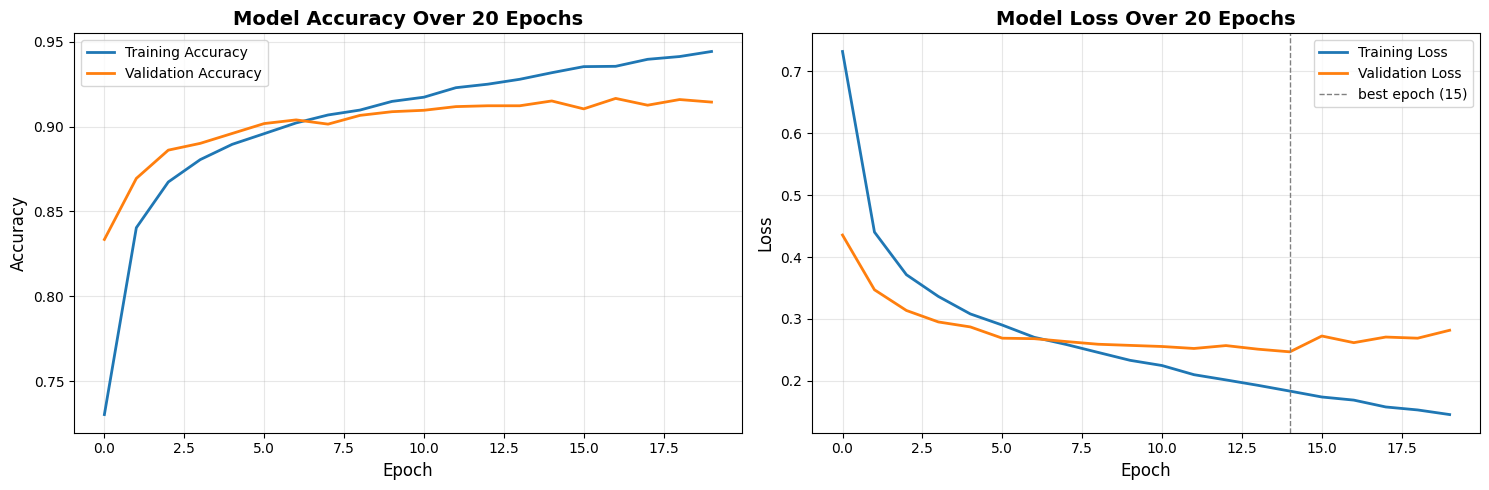


📊 Final Training Metrics:
  (values from the LAST epoch run; with early stopping the model itself was reset to the best epoch)
  Training Accuracy: 94.43%
  Validation Accuracy: 91.45%
  Training Loss: 0.1457
  Validation Loss: 0.2818


In [7]:
print("📈 Plotting training history...\n")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot accuracy
ax1.plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.set_title(f'Model Accuracy Over {epochs_run} Epochs', fontsize=14, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# Plot loss
ax2.plot(history.history['loss'], label='Training Loss', linewidth=2)
ax2.plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Loss', fontsize=12)
ax2.set_title(f'Model Loss Over {epochs_run} Epochs', fontsize=14, fontweight='bold')
ax2.axvline(best_epoch - 1, color='gray', ls='--', lw=1, label=f'best epoch ({best_epoch})')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print final metrics
print(f"\n📊 Final Training Metrics:")
print("  (values from the LAST epoch run; with early stopping the model itself was reset to the best epoch)")
print(f"  Training Accuracy: {history.history['accuracy'][-1]*100:.2f}%")
print(f"  Validation Accuracy: {history.history['val_accuracy'][-1]*100:.2f}%")
print(f"  Training Loss: {history.history['loss'][-1]:.4f}")
print(f"  Validation Loss: {history.history['val_loss'][-1]:.4f}")

---
## 🎯 Cell 8: Evaluate on Test Set

In [8]:
print("🎯 Evaluating model on test set...\n")

test_loss, test_accuracy = model.evaluate(X_test_cnn, y_test_cat, verbose=0)

print("✅ Evaluation complete!\n")
print(f"📊 Test Results:")
print(f"  Test Accuracy: {test_accuracy*100:.2f}%")
print(f"  Test Loss: {test_loss:.4f}")
print(f"\n  Tested on {len(X_test):,} images")

🎯 Evaluating model on test set...



✅ Evaluation complete!

📊 Test Results:
  Test Accuracy: 90.95%
  Test Loss: 0.2669

  Tested on 10,000 images


---
## 🔍 Cell 9: Test on Random Images from Test Set

🔍 Testing on random images from test set...



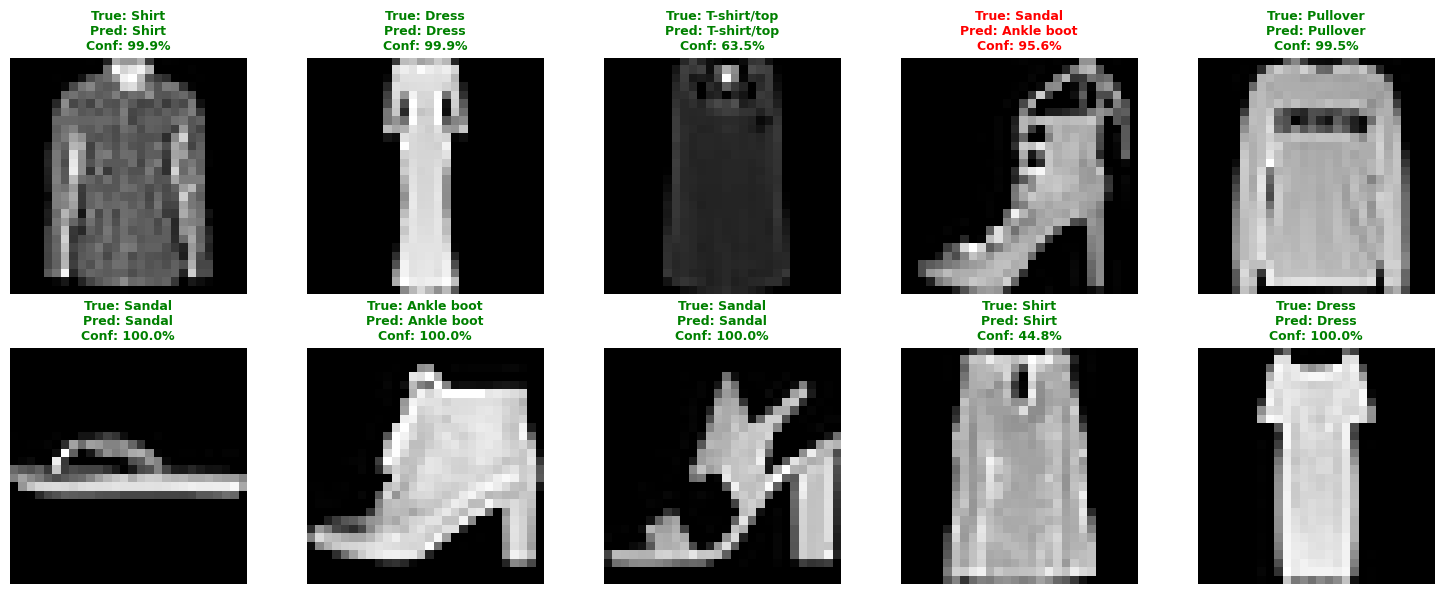


✅ Predictions complete!
  Green = Correct prediction
  Red = Incorrect prediction


In [9]:
print("🔍 Testing on random images from test set...\n")

# Select random test images
num_examples = 10
random_indices = np.random.choice(len(X_test), num_examples, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.ravel()

for i, idx in enumerate(random_indices):
    # Make prediction
    img = X_test_cnn[idx:idx+1]
    prediction = model.predict(img, verbose=0)
    predicted_class = np.argmax(prediction)
    confidence = prediction[0][predicted_class] * 100

    # Display image
    axes[i].imshow(X_test[idx], cmap='gray')

    # Color code: green for correct, red for incorrect
    color = 'green' if predicted_class == y_test[idx] else 'red'

    axes[i].set_title(
        f"True: {class_names[y_test[idx]]}\n"
        f"Pred: {class_names[predicted_class]}\n"
        f"Conf: {confidence:.1f}%",
        fontsize=9,
        color=color,
        fontweight='bold'
    )
    axes[i].axis('off')

plt.tight_layout()
plt.show()

print(f"\n✅ Predictions complete!")
print(f"  Green = Correct prediction")
print(f"  Red = Incorrect prediction")

---
## 🎨 Cell 10: Test on Specific Index

🎯 Enter an index (0-9999) to test a specific image:



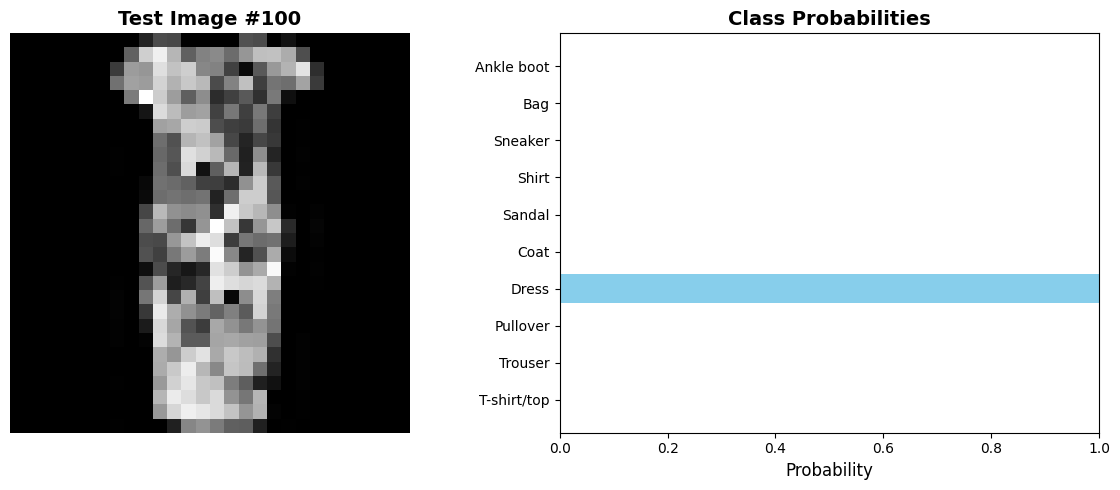


📊 Prediction Results:
  True label: 3 (Dress)
  Predicted: 3 (Dress)
  Confidence: 99.96%
  ✅ CORRECT!

  Top 3 predictions:
    1. Dress: 99.96%
    2. T-shirt/top: 0.04%
    3. Shirt: 0.00%


In [10]:
def test_specific_image(index=0):
    """Test a specific image from the test set"""
    if index < 0 or index >= len(X_test):
        print(f"❌ Please enter a number between 0 and {len(X_test)-1}")
        return

    # Make prediction
    img = X_test_cnn[index:index+1]
    prediction = model.predict(img, verbose=0)
    predicted_class = np.argmax(prediction)
    confidence = prediction[0][predicted_class] * 100

    # Create visualization
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    # Show image
    ax1.imshow(X_test[index], cmap='gray')
    ax1.set_title(f"Test Image #{index}", fontsize=14, fontweight='bold')
    ax1.axis('off')

    # Show prediction probabilities
    ax2.barh(class_names, prediction[0], color='skyblue')
    ax2.set_xlabel('Probability', fontsize=12)
    ax2.set_title('Class Probabilities', fontsize=14, fontweight='bold')
    ax2.set_xlim([0, 1])

    plt.tight_layout()
    plt.show()

    # Print results
    print(f"\n📊 Prediction Results:")
    print(f"  True label: {y_test[index]} ({class_names[y_test[index]]})")
    print(f"  Predicted: {predicted_class} ({class_names[predicted_class]})")
    print(f"  Confidence: {confidence:.2f}%")

    if predicted_class == y_test[index]:
        print(f"  ✅ CORRECT!")
    else:
        print(f"  ❌ INCORRECT")

    print(f"\n  Top 3 predictions:")
    top_3 = np.argsort(prediction[0])[-3:][::-1]
    for rank, cls in enumerate(top_3, 1):
        print(f"    {rank}. {class_names[cls]}: {prediction[0][cls]*100:.2f}%")

# Test a specific image
print("🎯 Enter an index (0-9999) to test a specific image:\n")
test_specific_image(100)

---
## 📤 Cell 11: Upload YOUR Fashion Drawing!

**Drawing Tips:**
1. Use white paper with black pen/marker
2. Draw large and clear
3. Center your drawing
4. Take photo with good lighting
5. Try: T-shirt, Trouser, Dress, Sneaker, Bag, Boot, etc.

**Best Results:**
- Simple, clear shapes
- Good contrast (dark on light)
- Centered in frame

In [11]:
print("📤 Upload your fashion drawing!\n")
print("💡 Drawing tips:")
print("  • Use white paper, black pen/marker")
print("  • Draw large and clear, ONE closed outline")
print("  • Center your drawing")
print("  • Good lighting for photo")
print("  • Simple shapes work best!\n")

# Where does the drawing come from?
#  • In Google Colab: an upload button appears (cancel it to use the demo drawing instead).
#  • In Jupyter / VS Code: put your own file name in MY_IMAGES below.
#  • With neither, the notebook draws a demo "photo" of a pen drawing so every cell still runs.
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

MY_IMAGES = []      # e.g. ["my_tshirt.jpg"]  (used when not in Colab)

DEMO_SHAPES = {     # simple outlines, in a 400 x 400 drawing area
    'T-shirt/top': [(120, 60), (170, 60), (200, 90), (230, 60), (280, 60), (350, 130), (310, 175), (285, 150),
                    (285, 340), (115, 340), (115, 150), (90, 175), (50, 130)],
    'Trouser':     [(130, 50), (270, 50), (285, 350), (225, 350), (200, 140), (175, 350), (115, 350)],
    'Bag':         [(80, 150), (320, 150), (320, 330), (80, 330)],
    'Ankle boot':  [(210, 60), (300, 60), (310, 320), (55, 320), (60, 265), (120, 235), (200, 220)],   # toe left
}


def make_demo_drawing(item='T-shirt/top', path=None, seed=0):
    """Draw a simple pen outline of a fashion item on slightly uneven paper, like a phone photo."""
    rng = np.random.default_rng(seed)
    H = W = 400
    paper = np.linspace(228, 246, W)[None, :] * np.ones((H, 1)) + rng.normal(0, 4, (H, W))
    ink = np.zeros((H, W), np.uint8)
    pts = np.array(DEMO_SHAPES[item], np.int32)
    cv2.polylines(ink, [pts], True, 255, 7, cv2.LINE_AA)
    if item == 'Bag':                                   # a handle
        cv2.ellipse(ink, (200, 150), (70, 70), 0, 180, 360, 255, 7, cv2.LINE_AA)
    ink = ink.astype(float) / 255
    photo = np.clip(paper * (1 - ink) + 40 * ink, 0, 255).astype(np.uint8)
    path = path or 'demo_' + item.split('/')[0].replace(' ', '_').lower() + '.png'
    cv2.imwrite(path, cv2.cvtColor(photo, cv2.COLOR_GRAY2BGR))
    return path


def get_images(demo_items=('T-shirt/top',)):
    """Return a list of image file names to classify."""
    if IN_COLAB:
        uploaded = files.upload()
        if uploaded:
            return list(uploaded.keys())
    if MY_IMAGES:
        return list(MY_IMAGES)
    print(f"(No upload, so using a demo drawing of: {', '.join(demo_items)}. "
          "Add your own file names to MY_IMAGES, or run this in Colab to upload.)\n")
    return [make_demo_drawing(item) for item in demo_items]

uploaded = get_images(demo_items=('T-shirt/top',))
print("\n✅ Image ready:", uploaded[0])

📤 Upload your fashion drawing!

💡 Drawing tips:
  • Use white paper, black pen/marker
  • Draw large and clear, ONE closed outline
  • Center your drawing
  • Good lighting for photo
  • Simple shapes work best!

(No upload, so using a demo drawing of: T-shirt/top. Add your own file names to MY_IMAGES, or run this in Colab to upload.)


✅ Image ready: demo_t-shirt.png


---
## 🔍 Cell 12: Preprocess & Classify YOUR Drawing

Fashion-MNIST pictures are **filled** grey objects on black, trimmed so the item fills the frame. A pen drawing
is an *outline* on white. So the function separates ink from paper, **fills the outline in** (keeping small
openings such as a bag's handle open), crops to the item and scales its longest side to 28 pixels.

> **Why so much care?** The network only knows Fashion-MNIST-style pictures. Fed a thin outline, it is guessing.
> We tested both versions on four demo drawings with a quickly trained copy of this CNN: the first version
> (outline only) got 2 right, this one got 4. (Shirt and T-shirt/top remain easy to confuse, even for the full model.)


🔍 Processing: demo_t-shirt.png

📸 Original image shape: (400, 400)


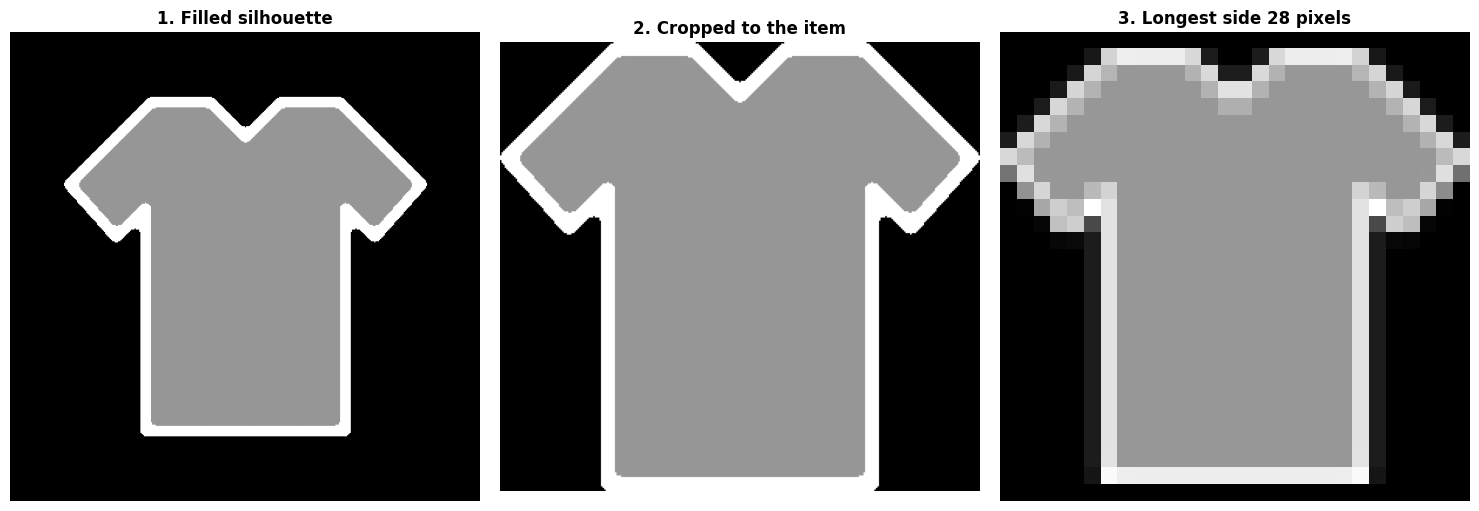


✅ Preprocessing complete!


In [12]:
def preprocess_fashion_image(filename):
    """
    Turn a photo of a fashion drawing (dark pen on light paper) into a Fashion-MNIST-style input.
    Returns: silhouette, cropped, resized 28x28 (0-255), model input (1, 28, 28, 1) -- or None.

    Fashion-MNIST pictures are FILLED, light objects on a black background, trimmed and scaled so the
    longest side fills the 28-pixel frame. An outline drawing is not that, so we fill the outline in.
    """
    img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)
    if img is None:
        print("❌ Could not read image!")
        return None, None, None, None
    print(f"📸 Original image shape: {img.shape}")

    blurred = cv2.GaussianBlur(img, (5, 5), 0)
    # Otsu: one threshold between paper and ink for the whole photo (ink becomes white)
    _, ink = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    # close small gaps in the pen line so the outline is one closed shape
    ink = cv2.morphologyEx(ink, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))

    contours, hierarchy = cv2.findContours(ink, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_SIMPLE)
    outer = [i for i in range(len(contours)) if hierarchy[0][i][3] == -1]
    if not outer:
        print("⚠️ Nothing found in the image.")
        return None, None, None, None
    k = max(outer, key=lambda i: cv2.contourArea(contours[i]))
    largest = contours[k]
    silhouette = np.zeros_like(ink)
    cv2.drawContours(silhouette, [largest], -1, 150, thickness=cv2.FILLED)   # fill the outline in, mid-grey
    # ...but keep SMALL enclosed openings (a bag's handle, the gap between trouser legs) open
    area = cv2.contourArea(largest)
    for i in range(len(contours)):
        if hierarchy[0][i][3] == k and cv2.contourArea(contours[i]) < 0.3 * area:
            cv2.drawContours(silhouette, contours, i, 0, thickness=cv2.FILLED)
    silhouette = np.maximum(silhouette, ink)                                  # keep your pen lines bright
    x, y, w, h = cv2.boundingRect(largest)
    cropped = silhouette[y:y+h, x:x+w]

    # longest side -> 28 pixels, keep the shape, centre in a 28x28 black frame
    scale = 28.0 / max(w, h)
    small = cv2.resize(cropped, (max(1, round(w * scale)), max(1, round(h * scale))), interpolation=cv2.INTER_AREA)
    resized = np.zeros((28, 28), dtype=np.uint8)
    top, left = (28 - small.shape[0]) // 2, (28 - small.shape[1]) // 2
    resized[top:top+small.shape[0], left:left+small.shape[1]] = small

    final = (resized.astype('float32') / 255.0).reshape(1, 28, 28, 1)
    return silhouette, cropped, resized, final

# Process the uploaded image
filename = uploaded[0]
print(f"\n🔍 Processing: {filename}\n")

original, cropped, resized, processed = preprocess_fashion_image(filename)

if processed is not None:
    # Visualize preprocessing steps
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(original, cmap='gray')
    axes[0].set_title('1. Filled silhouette', fontsize=12, fontweight='bold')
    axes[0].axis('off')

    axes[1].imshow(cropped, cmap='gray')
    axes[1].set_title('2. Cropped to the item', fontsize=12, fontweight='bold')
    axes[1].axis('off')

    axes[2].imshow(resized, cmap='gray')
    axes[2].set_title('3. Longest side 28 pixels', fontsize=12, fontweight='bold')
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

    print("\n✅ Preprocessing complete!")
else:
    print("\n❌ Preprocessing failed!")

---
## 🎯 Cell 13: AI Classification Result!

🤖 Classifying your fashion item...



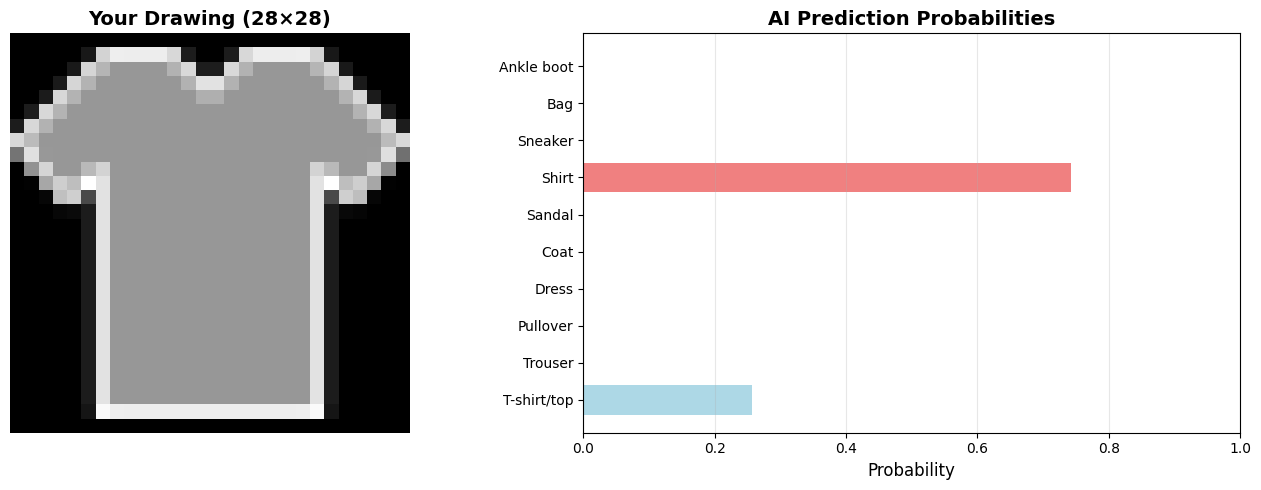


🎯 AI CLASSIFICATION RESULT

  🏆 Prediction: SHIRT
  📊 Confidence: 74.25%

  📈 Top 3 Predictions:
    🥇 Shirt: 74.25%
    🥈 T-shirt/top: 25.75%
    🥉 Pullover: 0.00%


👍 Confident prediction!


In [13]:
if processed is not None:
    print("🤖 Classifying your fashion item...\n")

    # Make prediction
    prediction = model.predict(processed, verbose=0)
    predicted_class = np.argmax(prediction)
    confidence = prediction[0][predicted_class] * 100

    # Create visualization
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Show processed image
    ax1.imshow(resized, cmap='gray')
    ax1.set_title(f"Your Drawing (28×28)", fontsize=14, fontweight='bold')
    ax1.axis('off')

    # Show prediction probabilities
    colors = ['lightcoral' if i == predicted_class else 'lightblue'
              for i in range(len(class_names))]
    ax2.barh(class_names, prediction[0], color=colors)
    ax2.set_xlabel('Probability', fontsize=12)
    ax2.set_title('AI Prediction Probabilities', fontsize=14, fontweight='bold')
    ax2.set_xlim([0, 1])
    ax2.grid(axis='x', alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Print results
    print("\n" + "="*60)
    print("🎯 AI CLASSIFICATION RESULT")
    print("="*60)
    print(f"\n  🏆 Prediction: {class_names[predicted_class].upper()}")
    print(f"  📊 Confidence: {confidence:.2f}%")

    print(f"\n  📈 Top 3 Predictions:")
    top_3 = np.argsort(prediction[0])[-3:][::-1]
    for rank, cls in enumerate(top_3, 1):
        emoji = "🥇" if rank == 1 else "🥈" if rank == 2 else "🥉"
        print(f"    {emoji} {class_names[cls]}: {prediction[0][cls]*100:.2f}%")

    print("\n" + "="*60)

    # Confidence interpretation
    if confidence >= 90:
        print("\n💪 Very confident prediction!")
    elif confidence >= 70:
        print("\n👍 Confident prediction!")
    elif confidence >= 50:
        print("\n🤔 Moderate confidence. Try drawing clearer!")
    else:
        print("\n😕 Low confidence. The drawing might be unclear.")
        print("   Try: simpler shapes, better contrast, clearer lines")
else:
    print("\n❌ Could not classify image. Please try again!")

---
## 🧠 Cell 14: How Does It Work?

In [14]:
print("\n" + "="*60)
print("🧠 HOW THE CNN WORKS")
print("="*60)

print("\n📚 CNN ARCHITECTURE:")
print("  1. Input: 28×28×1 grayscale image")
print("  2. Conv2D (32 filters, 3×3) → Extracts basic features")
print("  3. MaxPooling (2×2) → Reduces size, keeps important info")
print("  4. Conv2D (64 filters, 3×3) → Learns complex patterns")
print("  5. MaxPooling (2×2) → Further reduction")
print("  6. Conv2D (64 filters, 3×3) → High-level features")
print("  7. Flatten → Converts to 1D array")
print("  8. Dense (128) → Combines features")
print("  9. Dropout (0.5) → Prevents overfitting")
print("  10. Output (10) → Fashion class probabilities")

print("\n🔬 WHAT CNN LEARNS:")
print("  Layer 1: Edges, lines, basic shapes")
print("  Layer 2: Textures, patterns, clothing parts")
print("  Layer 3: Complete object features")
print("  Dense: Combines everything to classify")

print("\n⚙️ IMAGE PREPROCESSING:")
print("  1. Convert to grayscale")
print("  2. Gaussian blur (noise reduction)")
print("  3. Otsu threshold: separate ink from paper")
print("  4. Find the largest outline")
print("  5. Fill it in (Fashion-MNIST items are filled, not outlines)")
print("  6. Crop to the item")
print("  7. Scale the longest side to 28 pixels, centre in 28×28")
print("  8. Normalize (0-1 range)")
print("  9. Feed to CNN")
print("  10. Get classification & confidence!")

print("\n📊 TRAINING DETAILS:")
print(f"  • Epochs: {epochs_run} (best: {best_epoch})")
print(f"  • Batch size: 128")
print(f"  • Optimizer: Adam")
print(f"  • Loss: Categorical crossentropy")
print(f"  • Training samples: 54,000 (+6,000 held out for validation)")
print(f"  • Test samples: 10,000")
print(f"  • Classes: 10 fashion categories")

print("\n🎯 WHY STOP EARLY?")
print("  • After about 15-20 epochs the VALIDATION loss stops improving")
print("  • Training on makes the model memorise the training pictures")
print("  • Its mistakes stay the same, but it makes them more confidently")
print("  • Early stopping keeps the best epoch and saves ~90% of the compute")
print("  • Try REPRODUCE_ORIGINAL_200_EPOCHS = True once to see it for yourself")

print("\n💡 COMMON CONFUSIONS:")
print("  The AI sometimes confuses:")
print("  • Shirt and T-shirt (very similar)")
print("  • Pullover and Coat (similar shapes)")
print("  • Sneaker and Ankle boot (footwear)")
print("  • Draw distinct features to help AI!")

print("\n" + "="*60)


🧠 HOW THE CNN WORKS

📚 CNN ARCHITECTURE:
  1. Input: 28×28×1 grayscale image
  2. Conv2D (32 filters, 3×3) → Extracts basic features
  3. MaxPooling (2×2) → Reduces size, keeps important info
  4. Conv2D (64 filters, 3×3) → Learns complex patterns
  5. MaxPooling (2×2) → Further reduction
  6. Conv2D (64 filters, 3×3) → High-level features
  7. Flatten → Converts to 1D array
  8. Dense (128) → Combines features
  9. Dropout (0.5) → Prevents overfitting
  10. Output (10) → Fashion class probabilities

🔬 WHAT CNN LEARNS:
  Layer 1: Edges, lines, basic shapes
  Layer 2: Textures, patterns, clothing parts
  Layer 3: Complete object features
  Dense: Combines everything to classify

⚙️ IMAGE PREPROCESSING:
  1. Convert to grayscale
  2. Gaussian blur (noise reduction)
  3. Otsu threshold: separate ink from paper
  4. Find the largest outline
  5. Fill it in (Fashion-MNIST items are filled, not outlines)
  6. Crop to the item
  7. Scale the longest side to 28 pixels, centre in 28×28
  8. No

---
## 🎓 Cell 15: Project Summary

In [15]:
# Calculate final test accuracy
test_predictions = model.predict(X_test_cnn, verbose=0)
test_accuracy = np.mean(np.argmax(test_predictions, axis=1) == y_test)

print(f"\n{'='*60}")
print("🎓 PROJECT COMPLETE!")
print(f"{'='*60}")

print("\n🧠 WHAT WE DID:")
print("  • Explored Fashion MNIST dataset interactively")
print("  • Built CNN (Conv→Pool→Conv→Pool→Conv→Dense)")
print(f"  • Trained with early stopping (best epoch {best_epoch} of {epochs_run})")
print("  • Turned a pen drawing into a Fashion-MNIST-style picture")
print("  • Classified YOUR fashion drawing!")

print("\n📊 PERFORMANCE:")
print(f"  • Training accuracy: {history.history['accuracy'][-1]*100:.2f}%")
print(f"  • Validation accuracy: {history.history['val_accuracy'][-1]*100:.2f}%")
print(f"  • Test accuracy: {test_accuracy*100:.2f}%")
print(f"  • Trained on: 54,000 fashion images (+6,000 for validation)")
print(f"  • Tested on: 10,000 fashion images")
print(f"  • Training epochs: {epochs_run}")

print("\n🎯 KEY FEATURES:")
print("  ✓ Interactive Fashion MNIST explorer")
print("  ✓ CNN with 3 convolutional layers")
print("  ✓ MaxPooling for dimension reduction")
print("  ✓ Dropout for regularization")
print("  ✓ Early stopping keeps the best epoch")
print("  ✓ Auto-detect & crop uploads")
print("  ✓ Real-time classification")
print("  ✓ Confidence scores & probabilities")
print("  ✓ Beautiful visualizations")

print("\n👕 FASHION CATEGORIES LEARNED:")
for i, name in enumerate(class_names):
    print(f"  {i}: {name}")

print("\n🚀 NEXT STEPS:")
print("  • Try different CNN architectures")
print("  • Add data augmentation (rotation, zoom)")
print("  • Experiment with learning rates")
print("  • Try transfer learning (VGG16, ResNet)")
print("  • Build a mobile app")
print("  • Extend to colored fashion images")

print(f"\n{'='*60}")
print("✨ Awesome! You built a CNN fashion classifier! ✨")
print(f"{'='*60}")


🎓 PROJECT COMPLETE!

🧠 WHAT WE DID:
  • Explored Fashion MNIST dataset interactively
  • Built CNN (Conv→Pool→Conv→Pool→Conv→Dense)
  • Trained with early stopping (best epoch 15 of 20)
  • Turned a pen drawing into a Fashion-MNIST-style picture
  • Classified YOUR fashion drawing!

📊 PERFORMANCE:
  • Training accuracy: 94.43%
  • Validation accuracy: 91.45%
  • Test accuracy: 90.95%
  • Trained on: 54,000 fashion images (+6,000 for validation)
  • Tested on: 10,000 fashion images
  • Training epochs: 20

🎯 KEY FEATURES:
  ✓ Interactive Fashion MNIST explorer
  ✓ CNN with 3 convolutional layers
  ✓ MaxPooling for dimension reduction
  ✓ Dropout for regularization
  ✓ Early stopping keeps the best epoch
  ✓ Auto-detect & crop uploads
  ✓ Real-time classification
  ✓ Confidence scores & probabilities
  ✓ Beautiful visualizations

👕 FASHION CATEGORIES LEARNED:
  0: T-shirt/top
  1: Trouser
  2: Pullover
  3: Dress
  4: Coat
  5: Sandal
  6: Shirt
  7: Sneaker
  8: Bag
  9: Ankle boot

🚀 

---
## 🎁 BONUS: Confusion Matrix

📊 Generating Confusion Matrix...



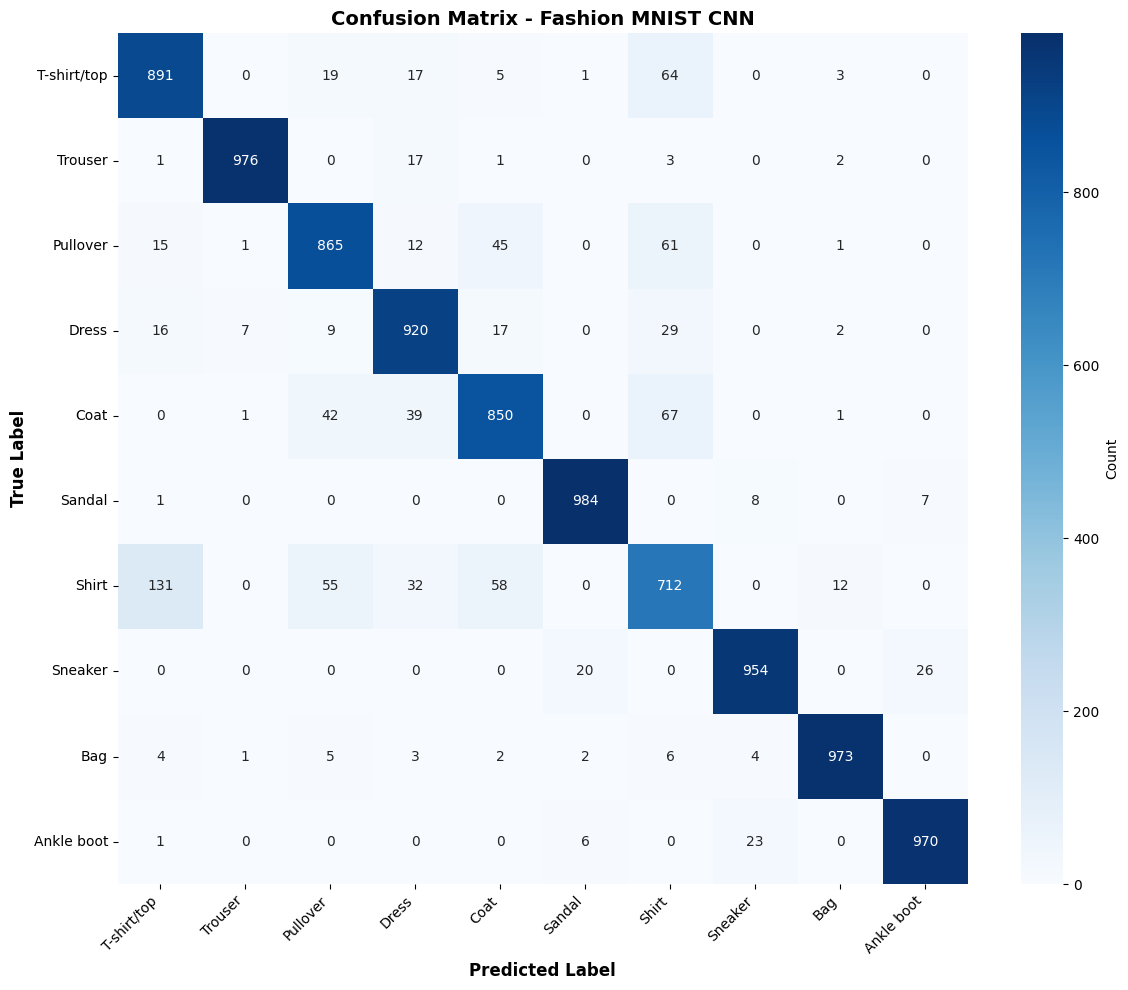


✅ Confusion matrix complete!

💡 How to read:
  • Diagonal = correct predictions
  • Off-diagonal = confusion between classes
  • Darker blue = more predictions


In [16]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

print("📊 Generating Confusion Matrix...\n")

# Get predictions for all test data
y_pred = np.argmax(model.predict(X_test_cnn, verbose=0), axis=1)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Count'})
plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontsize=12, fontweight='bold')
plt.title('Confusion Matrix - Fashion MNIST CNN', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("\n✅ Confusion matrix complete!")
print("\n💡 How to read:")
print("  • Diagonal = correct predictions")
print("  • Off-diagonal = confusion between classes")
print("  • Darker blue = more predictions")